In [ ]:
import os, uuid, requests
import numpy as np
from PIL import Image
from ddgs import DDGS

def mostly_white(p):
    a = np.asarray(Image.open(p).convert("L").resize((64, 64)))
    return (a > 235).mean() > 0.85

def clean(c):
    for f in os.listdir(f"dataset/{c}"):
        p = f"dataset/{c}/{f}"
        try:
            if mostly_white(p):
                os.remove(p)
        except Exception:
            os.remove(p)

for c in ["pen", "pencil", "eraser"]:
    clean(c)

headers = {"User-Agent": "Mozilla/5.0"}
qs = ["rubber eraser photo", "white rubber eraser real photo", "pink eraser stationery",
      "eraser held in hand", "eraser on desk with pencil", "colorful erasers"]
n = len(os.listdir("dataset/eraser"))
for q in qs:
    if n >= 80:
        break
    try:
        results = DDGS().images(q, max_results=60)
    except Exception:
        continue
    for r in results:
        if n >= 80:
            break
        try:
            resp = requests.get(r["image"], headers=headers, timeout=8)
            if resp.status_code == 200 and len(resp.content) > 5000:
                p = f"dataset/eraser/{uuid.uuid4().hex}.jpg"
                open(p, "wb").write(resp.content)
                Image.open(p).convert("RGB").save(p, "JPEG")
                if mostly_white(p):
                    os.remove(p)
                else:
                    n += 1
        except Exception:
            pass

for c in ["pen", "pencil", "eraser"]:
    print(c, len(os.listdir(f"dataset/{c}")))

pen 74
pencil 76
eraser 80


In [ ]:
import tensorflow as tf
from tensorflow import keras

args = dict(image_size=(224, 224), batch_size=16, validation_split=0.2, seed=42)
train = keras.utils.image_dataset_from_directory("dataset", subset="training", **args)
val = keras.utils.image_dataset_from_directory("dataset", subset="validation", **args)
classes = train.class_names
print(classes)

base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

model = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.Rescaling(1./127.5, offset=-1),
    base,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train, validation_data=val, epochs=10)

loss, acc = model.evaluate(val)
print(f"Validation accuracy: {acc:.2%}")

Found 230 files belonging to 3 classes.
Using 184 files for training.
Found 230 files belonging to 3 classes.
Using 46 files for validation.
['eraser', 'pen', 'pencil']
Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.4674 - loss: 1.1447 - val_accuracy: 0.6304 - val_loss: 0.8885
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.7446 - loss: 0.5956 - val_accuracy: 0.6957 - val_loss: 0.6588
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.8424 - loss: 0.4249 - val_accuracy: 0.8043 - val_loss: 0.5687
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8967 - loss: 0.3170 - val_accuracy: 0.8478 - val_loss: 0.5082
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.9348 - loss: 0.2765 - val_accuracy: 0.8478 - val_loss: 0.4730
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9348 - loss: 0.2307 - val_accuracy: 0.8478 - val_loss: 0.4618
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9293 - loss

In [ ]:
   model.save("pen_pencil_eraser.keras")
   open("labels.txt", "w").write("\n".join(classes))

   from google.colab import files
   files.download("pen_pencil_eraser.keras")
   files.download("labels.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

pen -> 80 images
pencil -> 80 images
eraser -> 80 images
Found 240 files belonging to 3 classes.
Using 192 files for training.
Found 240 files belonging to 3 classes.
Using 48 files for validation.
['eraser', 'pen', 'pencil']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.4323 - loss: 1.1138 - val_accuracy: 0.7500 - val_loss: 0.6173
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.7708 - loss: 0.5428 - val_accuracy: 0.8750 - val_loss: 0.3692
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 910ms/step - accuracy: 0.9219 - loss: 0.2821 - val_accuracy: 0.8542 - val_loss: 0.3555
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 988ms/step - accuracy: 0.9427 - loss: 0.2497 - val_accuracy: 0.8958 - val_loss: 0.2928
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 906ms/step - accuracy: 0.9531 - loss: 0.1892 - val_accuracy: 0.9167 - val_loss: 0.2663
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 20s 843ms/step - accuracy: 0.9635 - loss: 0.1262

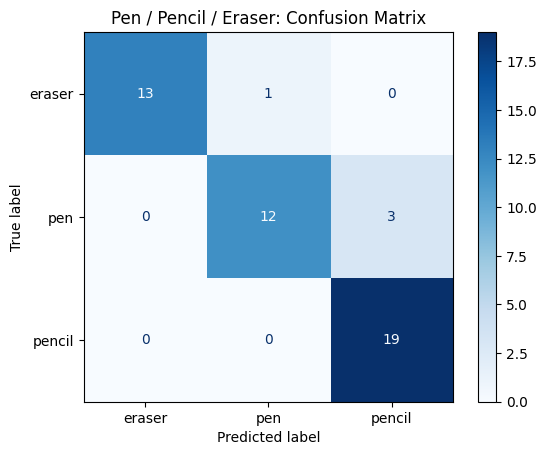

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q ddgs

import os, uuid, requests, numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ddgs import DDGS
from tensorflow import keras
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

queries = {
    "pen": ["ballpoint pen", "blue pen close up", "pen in hand writing", "black pen on table", "gel pen"],
    "pencil": ["wooden pencil", "pencil close up", "pencil in hand writing", "HB pencil on table", "yellow pencil"],
    "eraser": ["rubber eraser photo", "white rubber eraser real photo", "pink eraser stationery", "eraser held in hand", "colorful erasers"],
}
headers = {"User-Agent": "Mozilla/5.0"}

def mostly_white(p):
    a = np.asarray(Image.open(p).convert("L").resize((64, 64)))
    return (a > 235).mean() > 0.85

# 1. Download and clean images
for label, qs in queries.items():
    os.makedirs(f"dataset/{label}", exist_ok=True)
    n = len(os.listdir(f"dataset/{label}"))
    for q in qs:
        if n >= 80:
            break
        try:
            results = DDGS().images(q, max_results=60)
        except Exception:
            continue
        for r in results:
            if n >= 80:
                break
            p = None
            try:
                resp = requests.get(r["image"], headers=headers, timeout=8)
                if resp.status_code == 200 and len(resp.content) > 5000:
                    p = f"dataset/{label}/{uuid.uuid4().hex}.jpg"
                    open(p, "wb").write(resp.content)
                    Image.open(p).convert("RGB").save(p, "JPEG")
                    if mostly_white(p):
                        os.remove(p)
                    else:
                        n += 1
            except Exception:
                if p and os.path.exists(p):
                    os.remove(p)
    print(label, "->", len(os.listdir(f"dataset/{label}")), "images")

# 2. Train
args = dict(image_size=(224, 224), batch_size=16, validation_split=0.2, seed=42)
train = keras.utils.image_dataset_from_directory("dataset", subset="training", **args)
val = keras.utils.image_dataset_from_directory("dataset", subset="validation", **args)
classes = train.class_names
print(classes)

base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False
model = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.Rescaling(1./127.5, offset=-1),
    base,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train, validation_data=val, epochs=10)

# 3. Accuracy
loss, acc = model.evaluate(val)
print(f"Validation accuracy: {acc:.2%}")

# 4. Confusion matrix
y_true, y_pred = [], []
for x, y in val:
    y_true += list(y.numpy())
    y_pred += list(np.argmax(model.predict(x, verbose=0), axis=1))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap="Blues")
plt.title("Pen / Pencil / Eraser: Confusion Matrix")
plt.show()

# 5. Save and download
model.save("pen_pencil_eraser.keras")
open("labels.txt", "w").write("\n".join(classes))
from google.colab import files
files.download("pen_pencil_eraser.keras")
files.download("labels.txt")